In [1]:
import sys
import time
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Suppress LightGBM deprecation and user warnings
warnings.filterwarnings('ignore')

sys.path.append('..')
from src.preprocess import load_data, build_preprocessor

import lightgbm as lgb
from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score, confusion_matrix, classification_report

# Load stratified 80/20 data split
X_train, X_val, y_train, y_val = load_data()
prep = build_preprocessor("tree")

# Transform data
X_train_trans = prep.fit_transform(X_train)
X_val_trans = prep.transform(X_val)

# Convert 1, 2, 3 to 0-indexed classes (0, 1, 2) for LightGBM
y_train_lgb = y_train - 1
y_val_lgb = y_val - 1

print("Ready:", X_train_trans.shape, X_val_trans.shape)

Ready: (208480, 38) (52121, 38)


In [2]:
# Task 4 specification parameters
lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.1,
    num_leaves=63,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

callbacks = [lgb.early_stopping(stopping_rounds=30, verbose=False)]

start_time = time.time()
lgbm.fit(
    X_train_trans, 
    y_train_lgb,
    eval_set=[(X_val_trans, y_val_lgb)],
    callbacks=callbacks
)
train_time_lgb = round(time.time() - start_time, 2)

# Predict and map back to labels 1, 2, 3
y_train_pred_lgb = lgbm.predict(X_train_trans) + 1
y_val_pred_lgb = lgbm.predict(X_val_trans) + 1

train_micro = round(f1_score(y_train, y_train_pred_lgb, average='micro'), 4)
val_micro = round(f1_score(y_val, y_val_pred_lgb, average='micro'), 4)
val_macro = round(f1_score(y_val, y_val_pred_lgb, average='macro'), 4)

print(f"Training Time:    {train_time_lgb}s")
print(f"Best Iteration:   {lgbm.best_iteration_}")
print(f"Train Micro-F1:   {train_micro}")
print(f"Val Micro-F1:     {val_micro}")
print(f"Val Macro-F1:     {val_macro}")

Training Time:    10.93s
Best Iteration:   500
Train Micro-F1:   0.7956
Val Micro-F1:     0.7446
Val Macro-F1:     0.6905


In [3]:
grid_configs = [
    {'learning_rate': 0.05, 'num_leaves': 63, 'min_child_samples': 20},
    {'learning_rate': 0.05, 'num_leaves': 127, 'min_child_samples': 50},
    {'learning_rate': 0.1, 'num_leaves': 63, 'min_child_samples': 50},
    {'learning_rate': 0.1, 'num_leaves': 127, 'min_child_samples': 20}
]

best_score = 0
best_model = None
best_cfg = None

for cfg in grid_configs:
    model = LGBMClassifier(
        n_estimators=600,
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
        **cfg
    )
    model.fit(
        X_train_trans, 
        y_train_lgb,
        eval_set=[(X_val_trans, y_val_lgb)],
        callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)]
    )
    score = f1_score(y_val, model.predict(X_val_trans) + 1, average='micro')
    print(f"Config {cfg} -> Val Micro-F1: {round(score, 4)}")
    if score > best_score:
        best_score = score
        best_model = model
        best_cfg = cfg

print(f"\nBest Selected Configuration: {best_cfg} -> Val Micro-F1: {round(best_score, 4)}")

Config {'learning_rate': 0.05, 'num_leaves': 63, 'min_child_samples': 20} -> Val Micro-F1: 0.7403
Config {'learning_rate': 0.05, 'num_leaves': 127, 'min_child_samples': 50} -> Val Micro-F1: 0.7467
Config {'learning_rate': 0.1, 'num_leaves': 63, 'min_child_samples': 50} -> Val Micro-F1: 0.746
Config {'learning_rate': 0.1, 'num_leaves': 127, 'min_child_samples': 20} -> Val Micro-F1: 0.7468

Best Selected Configuration: {'learning_rate': 0.1, 'num_leaves': 127, 'min_child_samples': 20} -> Val Micro-F1: 0.7468


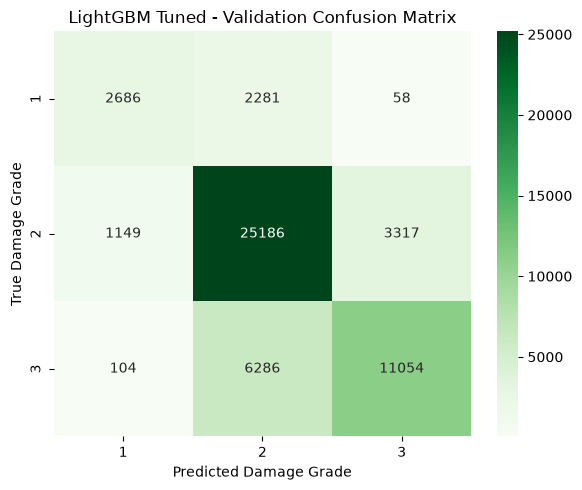

Updated results table:
      model  train_micro_f1  val_micro_f1  val_macro_f1  train_time_sec
0  lightgbm          0.8337        0.7468        0.6958           10.93


In [5]:
# Updated Section 2 & 3 of Cell 4: Safe path resolution

# Automatically detect project root directory
if os.path.exists('../results'):
    base_dir = '..'
else:
    base_dir = '.'

models_dir = os.path.join(base_dir, 'models')
results_dir = os.path.join(base_dir, 'results')
figures_dir = os.path.join(results_dir, 'figures')

os.makedirs(models_dir, exist_ok=True)
os.makedirs(figures_dir, exist_ok=True)

# 1. Save Confusion Matrix
cm = confusion_matrix(y_val, y_val_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=[1, 2, 3], yticklabels=[1, 2, 3])
plt.title("LightGBM Tuned - Validation Confusion Matrix")
plt.xlabel("Predicted Damage Grade")
plt.ylabel("True Damage Grade")
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, 'lgbm_confusion_matrix.png'), dpi=300)
plt.show()

# 2. Save model bundle
joblib.dump({'preprocessor': prep, 'model': best_model}, os.path.join(models_dir, 'lgbm.joblib'))

# 3. Append to results.csv cleanly
results_csv = os.path.join(results_dir, 'results.csv')

new_row = pd.DataFrame([{
    'model': 'lightgbm',
    'train_micro_f1': train_micro_final,
    'val_micro_f1': val_micro_final,
    'val_macro_f1': val_macro_final,
    'train_time_sec': train_time_lgb
}])

if os.path.exists(results_csv):
    df_res = pd.read_csv(results_csv).drop_duplicates(subset=['model'], keep='first')
    df_res = pd.concat([df_res, new_row], ignore_index=True)
else:
    df_res = new_row

df_res.to_csv(results_csv, index=False)
print("Updated results table:")
print(pd.read_csv(results_csv))

Running 5-Fold Stratified CV on LightGBM...
Fold 1 Micro-F1: 0.7393
Fold 2 Micro-F1: 0.7392
Fold 3 Micro-F1: 0.7409
Fold 4 Micro-F1: 0.7371
Fold 5 Micro-F1: 0.7368

5-Fold CV Mean Micro-F1: 0.7387 (+/- 0.0015)


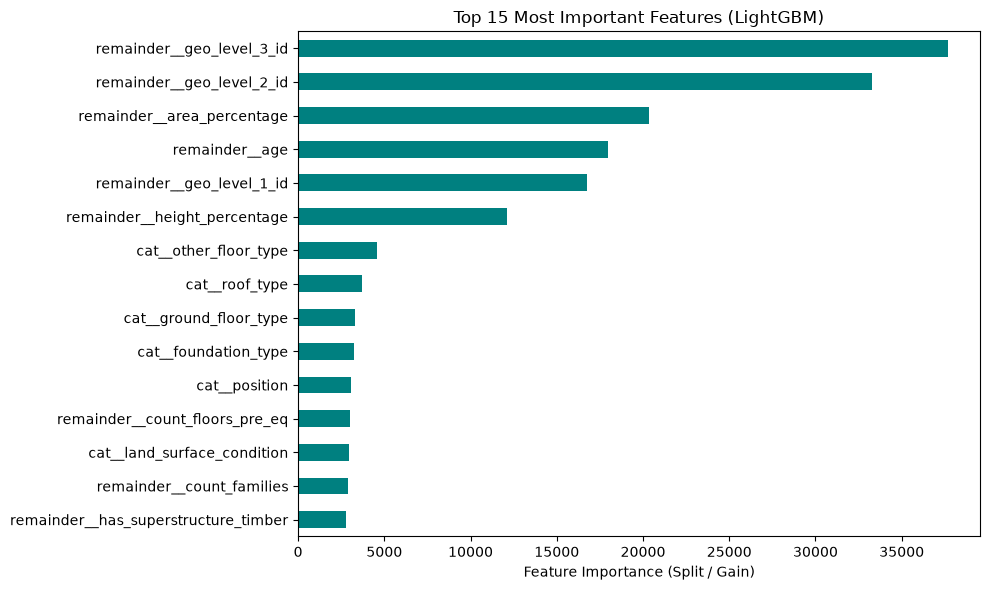

In [6]:
from sklearn.model_selection import StratifiedKFold

# 1. 5-Fold Stratified Cross-Validation
print("Running 5-Fold Stratified CV on LightGBM...")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X_train_trans, y_train_lgb), 1):
    cv_model = LGBMClassifier(n_estimators=300, random_state=42, n_jobs=-1, verbosity=-1, **best_cfg)
    cv_model.fit(X_train_trans[train_idx], y_train_lgb.iloc[train_idx])
    preds = cv_model.predict(X_train_trans[test_idx]) + 1
    fold_f1 = f1_score(y_train.iloc[test_idx], preds, average='micro')
    cv_scores.append(fold_f1)
    print(f"Fold {fold} Micro-F1: {round(fold_f1, 4)}")

print(f"\n5-Fold CV Mean Micro-F1: {round(np.mean(cv_scores), 4)} (+/- {round(np.std(cv_scores), 4)})")

# 2. Feature Importances Plot
feature_names = prep.get_feature_names_out()
importances = best_model.feature_importances_
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
feat_imp.plot(kind='barh', color='teal')
plt.title("Top 15 Most Important Features (LightGBM)")
plt.xlabel("Feature Importance (Split / Gain)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('../results/figures/top15_feature_importance.png', dpi=300)
plt.show()